# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [4]:
ROLL_NO = 1024170139          # <-- your full roll number
NAME = "Sparsh Khandelwal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [5]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [6]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [7]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170139   Name: Sparsh Khandelwal   Fingerprint: 27D41606   Tickets: 16

Ticket_ID                                                                                 Ticket_Text
      T01                                                                 My roll no. is 1023-03-021.
      T02                                                 I can't login and I didn't change anything.
      T03                                                          Dr. Rao's lab PC (No. 14) is down.
      T04 I couldn't connect to the server when connected to campus Wi-Fi. Is there another solution?
      T05                                                 The VPN failed to open. Can you check this?
      T06                       The student portal keeps asking for login. I don't know what changed.
      T07                           I can't open the laptop on my laptop. I have tried several times!
      T08                                                        Python 3.12 was installed yest

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [8]:
rows = []
for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    rows.append({
    "Ticket_ID": row["Ticket_ID"],
    "Sentences": len(result["sentences"]),
    "Tokens": len(result["tokens"]),
    "Punctuation": len(result["punct"]),
    "Stopwords": len(result["stops"]),
    "Unique_Tokens": len(set(result["tokens"])),
    "Final_Tokens": len(result["final"])
})

q1_table = pd.DataFrame(rows)

total_row = {
"Ticket_ID": "TOTAL",
"Sentences": q1_table["Sentences"].sum(),
"Tokens": q1_table["Tokens"].sum(),
"Punctuation": q1_table["Punctuation"].sum(),
"Stopwords": q1_table["Stopwords"].sum(),
"Unique_Tokens": q1_table["Unique_Tokens"].sum(),
"Final_Tokens": q1_table["Final_Tokens"].sum()
}

q1_table = pd.concat(
[q1_table, pd.DataFrame([total_row])],
ignore_index=True
)

print(q1_table.to_string(index=False))

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2       7            2          3              6             2
      T02          1      11            1          4              9             6
      T03          2      13            4          3             12             6
      T04          2      18            2          7             17             9
      T05          2      11            2          5             11             4
      T06          2      15            2          5             14             8
      T07          2      16            2          6             14             8
      T08          1       6            1          1              6             4
      T09          2      14            2          8             13             4
      T10          2      11            2          4             11             5
      T11          2      13            2          4             13             7
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [9]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re


raw_tickets = df["Ticket_Text"].tolist()


print("===== WORDS LONGER THAN 5 LETTERS =====")

for text in raw_tickets:
    print(re.findall(r"\b[A-Za-z]{6,}\b", text))

print("\n===== NUMBERS =====")

for text in raw_tickets:
    print(re.findall(r"\b\d+(?:\.\d+)*\b", text))


print("\n===== CAPITALIZED WORDS =====")

for text in raw_tickets:
    print(re.findall(r"\b[A-Z][a-zA-Z]*\b", text))


print("\n===== WORDS STARTING WITH A VOWEL =====")

for text in raw_tickets:
    print(re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", text))


email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s]+|www\.[^\s]+"

phone_pattern = r"(?<!\d)(?:\+91[\s-]?\d{5}[\s-]?\d{5}|\d{4}[-\s]\d{3}[-\s]\d{4})(?!\d)"


print("\n===== REGEX REPLACEMENT =====")

for text in raw_tickets:
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    print(text)


print("\n===== TEST_LINES =====")

for text in TEST_LINES:
    print("\nOriginal:", text)
    print("Long words:", re.findall(r"\b[A-Za-z]{6,}\b", text))
    print("Numbers:", re.findall(r"\b\d+(?:\.\d+)*\b", text))
    print("Capitalized words:", re.findall(r"\b[A-Z][a-zA-Z]*\b", text))
    print("Vowel words:", re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", text))

    replaced = re.sub(email_pattern, "<EMAIL>", text)
    replaced = re.sub(url_pattern, "<URL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)

    print("Replaced:", replaced)

===== WORDS LONGER THAN 5 LETTERS =====
[]
['change', 'anything']
[]
['couldn', 'connect', 'server', 'connected', 'campus', 'another', 'solution']
['failed']
['student', 'portal', 'asking', 'changed']
['laptop', 'laptop', 'several']
['Python', 'installed', 'yesterday']
['cannot', 'access', 'Python', 'laptop', 'urgent']
['working', 'yesterday', 'another', 'solution']
['Matlab', 'disconnecting', 'uploading', 'another', 'solution']
['Server', 'failed', 'restarting', 'system', 'Please', 'resolve']
['Server', 'crashes', 'opening', 'connected', 'campus', 'Please']
['MATLAB', 'stopped', 'syncing', 'mobile', 'hotspot', 'Please']
['restarting', 'Python', 'restarting', 'system', 'another', 'computer']
['restarting', 'projector', 'uploading']

===== NUMBERS =====
['1023', '03', '021']
[]
['14']
[]
[]
[]
[]
['3.12']
[]
[]
[]
[]
[]
[]
[]
[]

===== CAPITALIZED WORDS =====
['My']
['I', 'I']
['Dr', 'Rao', 'PC', 'No']
['I', 'Wi', 'Fi', 'Is']
['The', 'VPN', 'Can']
['The', 'I']
['I', 'I']
['Python']
['I'

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [10]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+91(?:[\s-]?\d{5}){2}|\b\d{4}[-\s]\d{3}[-\s]\d{4}\b|\b\d+(?:\.\d+)+\b|\b\d+\b|[A-Za-z]+(?:'[A-Za-z]+)+|[A-Za-z]+(?:-[A-Za-z]+)+|[A-Za-z]+|[^\w\s]"

tokenizer = RegexpTokenizer(pattern)

my_tokenize = tokenizer.tokenize

print("===== TEST_LINES =====")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

    print("\n===== TICKETS =====")

    different_tickets = 0

    for _, row in df.iterrows():
        my_tokens = my_tokenize(row["Ticket_Text"])
        nltk_tokens = word_tokenize(row["Ticket_Text"])

        if my_tokens != nltk_tokens:
            different_tickets += 1

        print("\nTicket:", row["Ticket_ID"])
        print("my_tokenize:", my_tokens)
        print("word_tokenize:", nltk_tokens)

    print("\nNumber of tickets tokenized differently:", different_tickets)

===== TEST_LINES =====

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

===== TICKETS =====

Ticket: T01
my_tokenize: ['My', 'roll', 'no', '.', 'is', '1023', '-', '03', '-', '021', '.']
word_tokenize: ['My', 'roll', 'no', '.', 'is', '1023-03-021', '.']

Ticket: T02
my_tokenize: ['I', "can't", 'login', 'and', 'I', "didn't", 'change', 'anything', '.']
word_tokenize: ['I', 'ca', "n't", 'login', 'and', 'I', 'did', "n't", 'change', 'anything', '.']

Ticket: T03
my_tokenize: ['Dr', '.', "Rao's", 'lab', 'PC', '(', 'No', '.', '14', ')', 'is', 'down', '.']
word_tokenize: ['Dr.', 'Rao', "'s", 'la

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [12]:
# Your code
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)


unique_final_tokens = sorted(set(
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
))


porter = PorterStemmer()
lancaster = LancasterStemmer()


regex_stemmer = RegexpStemmer(
    r"(ing|ed|ly|s)$",
    min=4
)


lemmatizer = WordNetLemmatizer()


tagged_words = nltk.pos_tag(unique_final_tokens)

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN


results = []

for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(
        word,
        get_wordnet_pos(tag)
    )

    if len(set([
        porter_result,
        lancaster_result,
        regex_result,
        lemma_result
    ])) > 1:
        results.append({
        "Word": word,
        "Porter": porter_result,
        "Lancaster": lancaster_result,
        "Regexp": regex_result,
        "WordNet_Lemma": lemma_result,
        "POS": tag
      })


comparison_table = pd.DataFrame(results)

print("Total unique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(comparison_table))
display(comparison_table)

Total unique final tokens: 61
Words with differing outputs: 31


,Word,Porter,Lancaster,Regexp,WordNet_Lemma,POS
0,access,access,access,acces,access,NN
1,another,anoth,anoth,another,another,DT
2,anything,anyth,anyth,anyth,anything,NN
3,campus,campu,camp,campu,campus,VB
4,change,chang,chang,change,change,NN
5,changed,chang,chang,chang,change,VBD
6,computer,comput,comput,computer,computer,NN
7,crashes,crash,crash,crashe,crash,VB
8,file,file,fil,file,file,NN
9,installed,instal,instal,install,installed,JJ


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.


 S1 - All tokens
Total tokens: 205
Unique tokens: 100
TTR: 0.4878

 S2 - No punctuation
Total tokens: 173
Unique tokens: 95
TTR: 0.5491

 S3 - Final tokens
Total tokens: 100
Unique tokens: 61
TTR: 0.61

 S4 - S3 after Porter
Total tokens: 100
Unique tokens: 57
TTR: 0.57

===== TOP 10 WORDS IN S1 =====
[('.', 24), ('I', 10), ('the', 9), ("n't", 5), ('to', 5), ('?', 5), ('another', 4), ('restarting', 4), ('is', 3), ('when', 3)]

===== TOP 10 WORDS IN S3 =====
[("n't", 5), ('another', 4), ('restarting', 4), ('server', 3), ('solution', 3), ('open', 3), ('laptop', 3), ('tried', 3), ('python', 3), ('please', 3)]


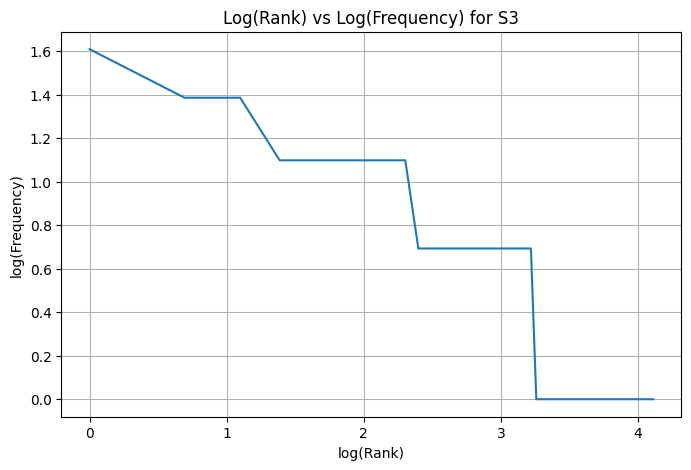


===== TOP 5 BIGRAMS IN S1 =====
[(('.', 'I'), 8), (('restarting', 'the'), 4), (('.', 'Is'), 3), (('Is', 'there'), 3), (('there', 'another'), 3)]

===== TOP 5 BIGRAMS IN S3 =====
[(('another', 'solution'), 3), (('ca', "n't"), 2), (('login', "n't"), 2), (('connected', 'campus'), 2), (('campus', 'wi-fi'), 2)]


In [13]:
# Your code
import re
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams


S1 = []

for text in df["Ticket_Text"]:
    tokens = word_tokenize(text)
    S1.extend(tokens)
S2 = []

for token in S1:
    if any(ch.isalnum() for ch in token):
        S2.append(token)



S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)
    S3.extend(result["final"])

from nltk.stem import PorterStemmer

porter = PorterStemmer()
S4 = []

for token in S3:
    S4.append(porter.stem(token))



def corpus_stats(name, tokens):
    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))

    if total_tokens > 0:
        ttr = unique_tokens / total_tokens
    else:
        ttr = 0

    print("\n", name)
    print("Total tokens:", total_tokens)
    print("Unique tokens:", unique_tokens)
    print("TTR:", round(ttr, 4))



corpus_stats("S1 - All tokens", S1)
corpus_stats("S2 - No punctuation", S2)
corpus_stats("S3 - Final tokens", S3)
corpus_stats("S4 - S3 after Porter", S4)



print("\n===== TOP 10 WORDS IN S1 =====")
print(Counter(S1).most_common(10))

print("\n===== TOP 10 WORDS IN S3 =====")
print(Counter(S3).most_common(10))



frequency = Counter(S3)
sorted_frequency = frequency.most_common()

ranks = []
log_frequencies = []

for rank, (word, count) in enumerate(sorted_frequency, start=1):
    ranks.append(math.log(rank))
    log_frequencies.append(math.log(count))

plt.figure(figsize=(8, 5))
plt.plot(ranks, log_frequencies)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()


# Top 5 bigrams in S1
print("\n===== TOP 5 BIGRAMS IN S1 =====")
S1_bigrams = Counter(bigrams(S1))
print(S1_bigrams.most_common(5))


# Top 5 bigrams in S3
print("\n===== TOP 5 BIGRAMS IN S3 =====")
S3_bigrams = Counter(bigrams(S3))
print(S3_bigrams.most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

TTR changes from S1 to S4 because Porter stemming converts different forms of a word into a common stem, reducing the number of unique tokens. Since TTR is the ratio of unique tokens to total tokens, it usually decreases after stemming, although the exact change depends on the dataset.